# Healthcare Operations Analytics & BI Dashboard

This notebook covers loading, profiling, cleaning and analysing operational records for a fictional Zimbabwean healthcare facility. It mimic the data i used for my project during my work at Corporate 24 Healthcare and i used it case study only. It does not contain Corporate 24 production data or real patient records.

## 1. Import the libraries

Pandas works with tables, NumPy supports numeric operations, and Matplotlib/Seaborn create charts.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
sns.set_theme()
print("Libraries loaded successfully")

Libraries loaded successfully


## 2. Set the project folders

In [2]:
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "Data"
OUTPUT_DIR = PROJECT_DIR / "Output"
CHART_DIR = OUTPUT_DIR / "Charts"
OUTPUT_DIR.mkdir(exist_ok=True)
CHART_DIR.mkdir(exist_ok=True)
print("Project folder:", PROJECT_DIR)
print("Data folder exists:", DATA_DIR.exists())
print("Data files:", [p.name for p in DATA_DIR.glob("*.csv")])

Project folder: C:\Users\Bunny\Downloads\Healthcare Analytics
Data folder exists: True
Data files: ['admissions.csv', 'bed_census_daily.csv', 'data_dictionary.csv', 'patient_master.csv', 'service_catalog.csv', 'staffing_daily.csv', 'visits_raw.csv']


## 3. Load the CSV files

In [3]:
visits_raw = pd.read_csv(DATA_DIR / "visits_raw.csv")
patients = pd.read_csv(DATA_DIR / "patient_master.csv")
admissions = pd.read_csv(DATA_DIR / "admissions.csv")
bed_census = pd.read_csv(DATA_DIR / "bed_census_daily.csv")
staffing = pd.read_csv(DATA_DIR / "staffing_daily.csv")
services = pd.read_csv(DATA_DIR / "service_catalog.csv")

print("Visits raw:", visits_raw.shape)
print("Patients:", patients.shape)
print("Admissions:", admissions.shape)
print("Bed census:", bed_census.shape)
print("Staffing:", staffing.shape)
print("Services:", services.shape)

Visits raw: (42150, 20)
Patients: (11000, 6)
Admissions: (2793, 12)
Bed census: (2924, 7)
Staffing: (4386, 6)
Services: (18, 3)


## 4. First inspection

Inspecting the first rows, column names, data types and missing values before changing data.

In [4]:
display(visits_raw.head(10))
visits_raw.info()
missing_overview = visits_raw.isna().sum().sort_values(ascending=False).to_frame("MissingRows")
missing_overview["MissingPercent"] = (missing_overview["MissingRows"] / len(visits_raw) * 100).round(2)
display(missing_overview)

,EncounterID,PatientID,VisitDate,ArrivalTime,Department,ServiceLine,VisitType,AppointmentType,Sex,AgeAtVisit,AgeBand,HomeDistrict,PayerType,ReferralSource,DiagnosisGroup,WaitMinutes,ConsultationMinutes,VisitStatus,Outcome,HasVitalsRecorded
0,ENC-0000001,SYN-P001534,2025-09-20,17:22,Outpatient,Chronic Care Review,Follow-up,Walk-in,Female,24,15-24,Harare South,Cash,Self,Respiratory,22.0,28.0,Completed,Discharged,True
1,ENC-0000002,SYN-P010473,2025-08-01,19:30,Emergency,Trauma Review,Follow-up,Scheduled,Female,20,15-24,Epworth,Cash,Clinic,Injury and Trauma,6.0,38.0,Completed,Referred,True
2,ENC-0000003,SYN-P002200,2025-11-16,12:25,Outpatient,Family Medicine,New,Referral,Female,6,5-14,Norton,Medical Aid,Self,Gastrointestinal,36.0,18.0,Completed,Discharged,True
3,ENC-0000004,SYN-P003689,2025-06-19,09:33,Outpatient,General Consultation,Follow-up,Scheduled,Male,49,45-64,Chitungwiza,Cash,Self,Cardiovascular,14.0,3.0,Completed,Discharged,True
4,ENC-0000005,SYN-P003589,2024-03-28,13:15,Emergency,Emergency Assessment,New,Walk-in,Female,19,15-24,Harare South,Medical Aid,Clinic,Gastrointestinal,139.0,31.0,Completed,Discharged,True
5,ENC-0000006,SYN-P003033,2024-03-26,11:14,Diagnostics,Laboratory,New,Scheduled,Female,27,25-44,Other Zimbabwe,Cash,Self,Infectious Disease,12.0,22.0,Completed,Referred,False
6,ENC-0000007,SYN-P001537,2025-05-24,11:48,Outpatient,General Consultation,Follow-up,Referral,Male,40,25-44,Other Zimbabwe,Corporate,General Practitioner,Injury and Trauma,NaN,NaN,Cancelled,Not Seen,True
7,ENC-0000008,SYN-P000409,2025-10-07,10:25,Paediatrics,Immunisation,New,Referral,Male,40,25-44,Other Zimbabwe,Medical Aid,Clinic,Musculoskeletal,91.0,20.0,Completed,Discharged,True
8,ENC-0000009,SYN-P002708,2025-06-02,08:46,Outpatient,Chronic Care Review,New,Walk-in,Male,51,45-64,Chitungwiza,Corporate,Clinic,Cardiovascular,34.0,20.0,Completed,Discharged,True
9,ENC-0000010,SYN-P005839,2025-02-07,19:16,Outpatient,General Consultation,New,Scheduled,Male,33,25-44,Ruwa,Medical Aid,General Practitioner,Respiratory,45.0,26.0,Completed,Discharged,True


<class 'pandas.DataFrame'>
RangeIndex: 42150 entries, 0 to 42149
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   EncounterID          42150 non-null  str    
 1   PatientID            42065 non-null  str    
 2   VisitDate            42150 non-null  str    
 3   ArrivalTime          42150 non-null  str    
 4   Department           42150 non-null  str    
 5   ServiceLine          42150 non-null  str    
 6   VisitType            42150 non-null  str    
 7   AppointmentType      42150 non-null  str    
 8   Sex                  42150 non-null  str    
 9   AgeAtVisit           42150 non-null  int64  
 10  AgeBand              42150 non-null  str    
 11  HomeDistrict         42150 non-null  str    
 12  PayerType            42150 non-null  str    
 13  ReferralSource       42150 non-null  str    
 14  DiagnosisGroup       42150 non-null  str    
 15  WaitMinutes          39115 non-null  float64
 1

,MissingRows,MissingPercent
WaitMinutes,3035,7.20
ConsultationMinutes,2914,6.91
PatientID,85,0.20
EncounterID,0,0.00
ArrivalTime,0,0.00
VisitDate,0,0.00
Department,0,0.00
ServiceLine,0,0.00
Sex,0,0.00
AgeAtVisit,0,0.00


## 5. Data-quality checks

In [5]:
quality_audit = pd.DataFrame({
    "Check": [
        "Rows in raw file",
        "Unique encounter IDs",
        "Duplicate encounter IDs",
        "Blank patient IDs",
        "Missing wait values",
        "Negative wait values",
        "Wait values above 240 minutes",
        "Negative consultation values",
        "Consultation values above 240 minutes"
    ],
    "Result": [
        len(visits_raw),
        visits_raw["EncounterID"].nunique(),
        visits_raw["EncounterID"].duplicated().sum(),
        (visits_raw["PatientID"].isna() | visits_raw["PatientID"].astype(str).str.strip().eq("")).sum(),
        visits_raw["WaitMinutes"].isna().sum(),
        (pd.to_numeric(visits_raw["WaitMinutes"], errors="coerce") < 0).sum(),
        (pd.to_numeric(visits_raw["WaitMinutes"], errors="coerce") > 240).sum(),
        (pd.to_numeric(visits_raw["ConsultationMinutes"], errors="coerce") < 0).sum(),
        (pd.to_numeric(visits_raw["ConsultationMinutes"], errors="coerce") > 240).sum()
    ]
})
display(quality_audit)
quality_audit.to_csv(OUTPUT_DIR / "data_quality_audit_before_cleaning.csv", index=False)

,Check,Result
0,Rows in raw file,42150
1,Unique encounter IDs,42000
2,Duplicate encounter IDs,150
3,Blank patient IDs,85
4,Missing wait values,3035
5,Negative wait values,36
6,Wait values above 240 minutes,35
7,Negative consultation values,25
8,Consultation values above 240 minutes,30


## 6. Clean the encounter table

Cleaning rules used here:

1. Keep one row per `EncounterID`.
2. Trim spaces and standardise department and payer labels.
3. Convert visit dates and numeric measures to appropriate data types.
4. Treat negative or implausibly high duration values as missing rather than silently accepting them.
5. Impute missing durations only for completed visits, using the median for that department. Missing durations for cancelled/no-show visits remain blank because no service was delivered.
6. Keep blank patient IDs blank and report them; do not invent patient keys.


In [6]:
visits = visits_raw.drop_duplicates(subset=["EncounterID"], keep="first").copy()
visits["PatientID"] = visits["PatientID"].astype(str).str.strip().replace({"": np.nan, "nan": np.nan})
visits["Department"] = visits["Department"].astype(str).str.strip()
visits["Department"] = visits["Department"].replace({
    "Out patient": "Outpatient",
    "Accident & Emergency": "Emergency"
})
visits["PayerType"] = visits["PayerType"].astype(str).str.strip().str.title()
visits["PayerType"] = visits["PayerType"].replace({"Medical Aid": "Medical Aid", "Cash": "Cash", "Corporate": "Corporate", "Staff": "Staff"})
visits["VisitDate"] = pd.to_datetime(visits["VisitDate"], errors="coerce")
for col in ["WaitMinutes", "ConsultationMinutes", "AgeAtVisit"]:
    visits[col] = pd.to_numeric(visits[col], errors="coerce")

# Invalid duration values are changed to missing for transparent handling.
visits.loc[(visits["WaitMinutes"] < 0) | (visits["WaitMinutes"] > 240), "WaitMinutes"] = np.nan
visits.loc[(visits["ConsultationMinutes"] < 1) | (visits["ConsultationMinutes"] > 240), "ConsultationMinutes"] = np.nan

completed = visits["VisitStatus"].eq("Completed")
for col in ["WaitMinutes", "ConsultationMinutes"]:
    medians = visits.loc[completed].groupby("Department")[col].transform("median")
    missing_completed = completed & visits[col].isna()
    visits.loc[missing_completed, col] = medians[missing_completed]

visits["VisitMonth"] = visits["VisitDate"].dt.to_period("M").astype(str)
visits["DayOfWeek"] = visits["VisitDate"].dt.day_name()
visits["VisitHour"] = pd.to_numeric(visits["ArrivalTime"].str.slice(0,2), errors="coerce")
print("Cleaned visit table:", visits.shape)
print("Remaining duplicate encounters:", visits["EncounterID"].duplicated().sum())
print("Blank patient keys retained:", visits["PatientID"].isna().sum())
display(visits.head())

Cleaned visit table: (42000, 23)
Remaining duplicate encounters: 0
Blank patient keys retained: 84


,EncounterID,PatientID,VisitDate,ArrivalTime,Department,ServiceLine,VisitType,AppointmentType,Sex,AgeAtVisit,AgeBand,HomeDistrict,PayerType,ReferralSource,DiagnosisGroup,WaitMinutes,ConsultationMinutes,VisitStatus,Outcome,HasVitalsRecorded,VisitMonth,DayOfWeek,VisitHour
0,ENC-0000001,SYN-P001534,2025-09-20,17:22,Outpatient,Chronic Care Review,Follow-up,Walk-in,Female,24,15-24,Harare South,Cash,Self,Respiratory,22.0,28.0,Completed,Discharged,True,2025-09,Saturday,17
1,ENC-0000002,SYN-P010473,2025-08-01,19:30,Emergency,Trauma Review,Follow-up,Scheduled,Female,20,15-24,Epworth,Cash,Clinic,Injury and Trauma,6.0,38.0,Completed,Referred,True,2025-08,Friday,19
2,ENC-0000003,SYN-P002200,2025-11-16,12:25,Outpatient,Family Medicine,New,Referral,Female,6,5-14,Norton,Medical Aid,Self,Gastrointestinal,36.0,18.0,Completed,Discharged,True,2025-11,Sunday,12
3,ENC-0000004,SYN-P003689,2025-06-19,09:33,Outpatient,General Consultation,Follow-up,Scheduled,Male,49,45-64,Chitungwiza,Cash,Self,Cardiovascular,14.0,3.0,Completed,Discharged,True,2025-06,Thursday,9
4,ENC-0000005,SYN-P003589,2024-03-28,13:15,Emergency,Emergency Assessment,New,Walk-in,Female,19,15-24,Harare South,Medical Aid,Clinic,Gastrointestinal,139.0,31.0,Completed,Discharged,True,2024-03,Thursday,13


## 7. Check the cleaned data

In [7]:
post_cleaning = pd.DataFrame({
    "Check": ["Rows after de-duplication", "Duplicate encounter IDs", "Blank patient IDs", "Completed visits missing wait",
              "Completed visits missing consultation", "Invalid wait values", "Invalid consultation values", "Missing visit dates"],
    "Result": [len(visits), visits["EncounterID"].duplicated().sum(), visits["PatientID"].isna().sum(),
               (completed & visits["WaitMinutes"].isna()).sum(), (completed & visits["ConsultationMinutes"].isna()).sum(),
               ((visits["WaitMinutes"] < 0) | (visits["WaitMinutes"] > 240)).sum(),
               ((visits["ConsultationMinutes"] < 1) | (visits["ConsultationMinutes"] > 240)).sum(), visits["VisitDate"].isna().sum()]
})
display(post_cleaning)
post_cleaning.to_csv(OUTPUT_DIR / "data_quality_audit_after_cleaning.csv", index=False)
visits.to_csv(OUTPUT_DIR / "visits_clean.csv", index=False)

,Check,Result
0,Rows after de-duplication,42000
1,Duplicate encounter IDs,0
2,Blank patient IDs,84
3,Completed visits missing wait,0
4,Completed visits missing consultation,0
5,Invalid wait values,0
6,Invalid consultation values,0
7,Missing visit dates,0


## 8. Patient-flow analysis

How many encounters occur each month?
Which departments receive the most visits?
How do waiting times differ by department?

In [8]:
completed_visits = visits[visits["VisitStatus"] == "Completed"].copy()
monthly_visits = visits.groupby("VisitMonth").agg(
    TotalVisits=("EncounterID", "count"),
    UniquePatients=("PatientID", "nunique"),
    CompletedVisits=("VisitStatus", lambda s: (s == "Completed").sum())
).reset_index()
department_summary = visits.groupby("Department").agg(
    TotalVisits=("EncounterID", "count"),
    UniquePatients=("PatientID", "nunique")
).reset_index().sort_values("TotalVisits", ascending=False)
wait_summary = completed_visits.groupby("Department").agg(
    AverageWaitMinutes=("WaitMinutes", "mean"),
    MedianWaitMinutes=("WaitMinutes", "median"),
    AverageConsultationMinutes=("ConsultationMinutes", "mean")
).reset_index().round(1)
display(monthly_visits.head())
display(department_summary)
display(wait_summary)
monthly_visits.to_csv(OUTPUT_DIR / "monthly_visits_summary.csv", index=False)
department_summary.to_csv(OUTPUT_DIR / "department_summary.csv", index=False)
wait_summary.to_csv(OUTPUT_DIR / "waiting_time_summary.csv", index=False)

,VisitMonth,TotalVisits,UniquePatients,CompletedVisits
0,2024-01,1518,1430,1420
1,2024-02,1557,1434,1467
2,2024-03,1633,1513,1536
3,2024-04,1693,1553,1613
4,2024-05,1767,1642,1657


,Department,TotalVisits,UniquePatients
3,Outpatient,17586,8831
1,Emergency,7133,5235
5,Surgical Clinic,4929,3954
4,Paediatrics,4680,3766
2,Maternity,4354,3599
0,Diagnostics,3318,2875


,Department,AverageWaitMinutes,MedianWaitMinutes,AverageConsultationMinutes
0,Diagnostics,24.2,21.0,15.8
1,Emergency,26.3,23.0,32.3
2,Maternity,31.4,27.0,28.1
3,Outpatient,38.4,33.0,20.0
4,Paediatrics,33.1,28.0,22.9
5,Surgical Clinic,43.8,37.0,29.9


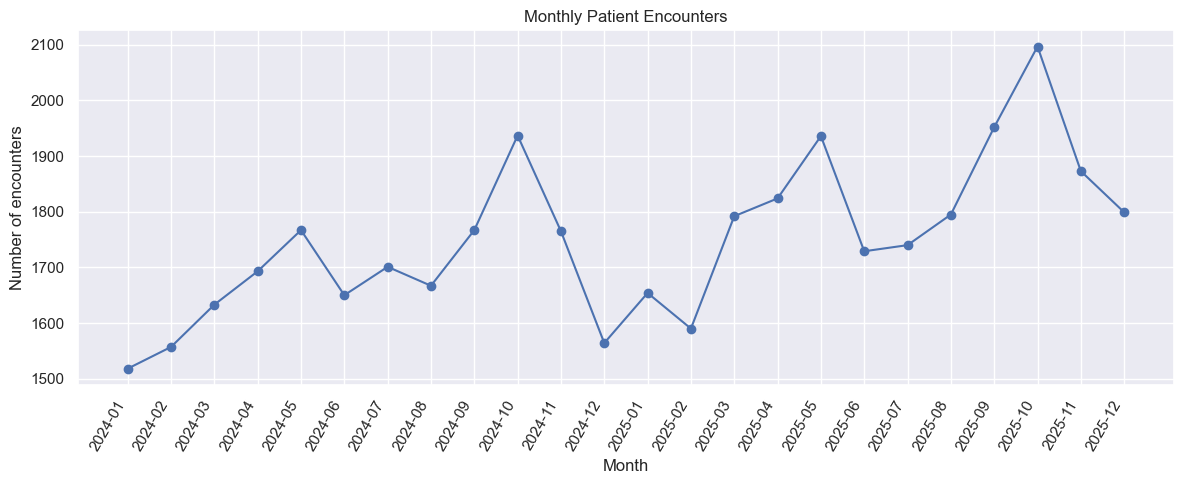

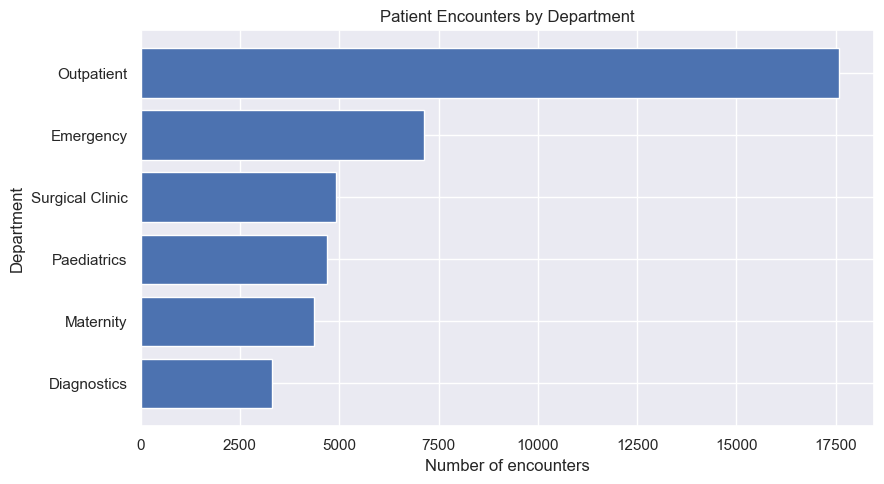

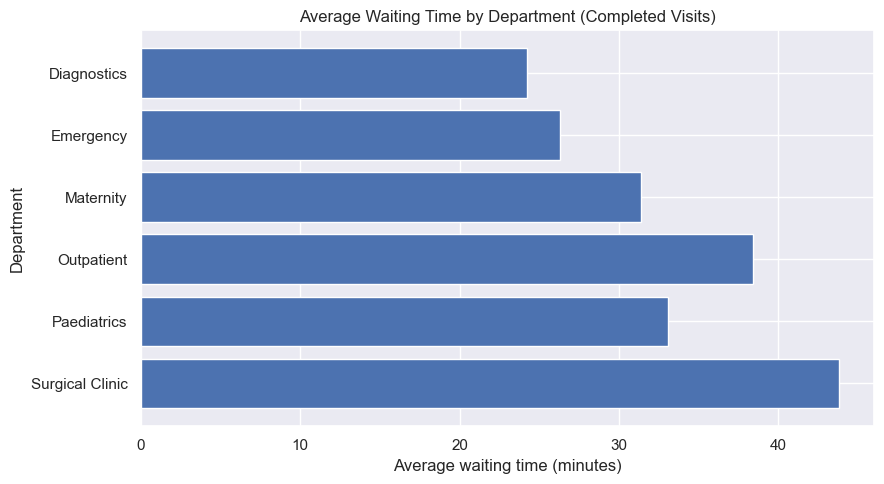

In [9]:
plt.figure(figsize=(12,5))
plt.plot(monthly_visits["VisitMonth"], monthly_visits["TotalVisits"], marker="o")
plt.title("Monthly Patient Encounters")
plt.xlabel("Month"); plt.ylabel("Number of encounters")
plt.xticks(rotation=60, ha="right"); plt.tight_layout()
plt.savefig(CHART_DIR / "monthly_patient_visits.png", dpi=180); plt.show()

plt.figure(figsize=(9,5))
plt.barh(department_summary["Department"], department_summary["TotalVisits"])
plt.gca().invert_yaxis()
plt.title("Patient Encounters by Department")
plt.xlabel("Number of encounters"); plt.ylabel("Department")
plt.tight_layout(); plt.savefig(CHART_DIR / "visits_by_department.png", dpi=180); plt.show()

plt.figure(figsize=(9,5))
plt.barh(wait_summary["Department"], wait_summary["AverageWaitMinutes"])
plt.gca().invert_yaxis()
plt.title("Average Waiting Time by Department (Completed Visits)")
plt.xlabel("Average waiting time (minutes)"); plt.ylabel("Department")
plt.tight_layout(); plt.savefig(CHART_DIR / "average_wait_by_department.png", dpi=180); plt.show()

## 9. Admissions and length of stay

Explore admission volume by month, ward and admission type. Compare average length of stay across wards.

,Ward,Admissions,AverageLengthOfStay,MedianLengthOfStay
0,Maternity Ward,322,5.1,4.0
1,Medical Ward,1801,4.6,4.0
2,Paediatric Ward,330,4.8,4.0
3,Surgical Ward,340,4.6,4.0


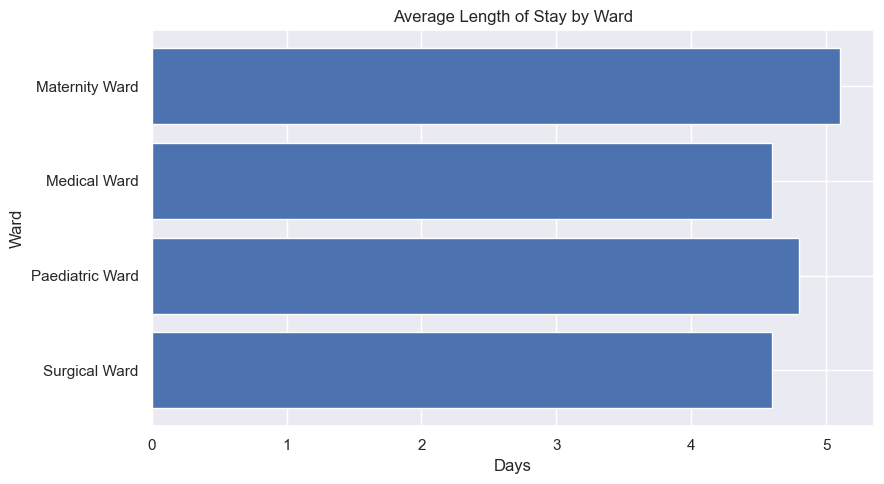

In [10]:
admissions["AdmissionDate"] = pd.to_datetime(admissions["AdmissionDate"], errors="coerce")
admissions["DischargeDate"] = pd.to_datetime(admissions["DischargeDate"], errors="coerce")
admissions["AdmissionMonth"] = admissions["AdmissionDate"].dt.to_period("M").astype(str)
los_summary = admissions.groupby("Ward").agg(
    Admissions=("AdmissionID", "count"),
    AverageLengthOfStay=("LengthOfStayDays", "mean"),
    MedianLengthOfStay=("LengthOfStayDays", "median")
).reset_index().round(1)
monthly_admissions = admissions.groupby("AdmissionMonth").size().rename("Admissions").reset_index()
display(los_summary)
los_summary.to_csv(OUTPUT_DIR / "length_of_stay_by_ward.csv", index=False)
monthly_admissions.to_csv(OUTPUT_DIR / "monthly_admissions.csv", index=False)

plt.figure(figsize=(9,5))
plt.barh(los_summary["Ward"], los_summary["AverageLengthOfStay"])
plt.gca().invert_yaxis()
plt.title("Average Length of Stay by Ward")
plt.xlabel("Days"); plt.ylabel("Ward")
plt.tight_layout(); plt.savefig(CHART_DIR / "average_los_by_ward.png", dpi=180); plt.show()

## 10. Bed-occupancy analysis

Occupancy is occupied beds divided by nominal bed capacity.

Facility weighted occupancy: 64.3 %


,Ward,AverageOccupancy,PeakOccupancy,DaysAbove85,CapacityBedDays,OccupiedBedDays,WeightedOccupancy
0,Maternity Ward,0.593,1.167,4,13158,7808,0.593
1,Medical Ward,0.715,1.062,23,23392,16727,0.715
2,Paediatric Ward,0.564,1.188,3,11696,6595,0.564
3,Surgical Ward,0.637,1.136,7,16082,10248,0.637


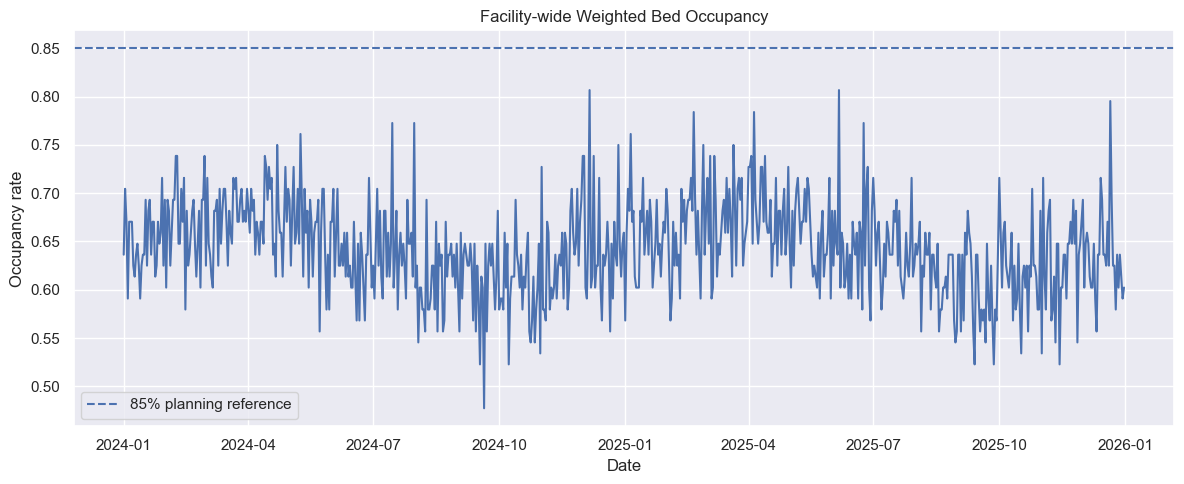

In [11]:
bed_census["Date"] = pd.to_datetime(bed_census["Date"], errors="coerce")
bed_census["OccupancyRate"] = pd.to_numeric(bed_census["OccupancyRate"], errors="coerce")
ward_occupancy = bed_census.groupby("Ward").agg(
    AverageOccupancy=("OccupancyRate", "mean"),
    PeakOccupancy=("OccupancyRate", "max"),
    DaysAbove85=("OccupancyRate", lambda s: (s > 0.85).sum()),
    CapacityBedDays=("BedCapacity", "sum"),
    OccupiedBedDays=("OccupiedBeds", "sum")
).reset_index()
ward_occupancy["WeightedOccupancy"] = ward_occupancy["OccupiedBedDays"] / ward_occupancy["CapacityBedDays"]
facility_weighted_occupancy = bed_census["OccupiedBeds"].sum() / bed_census["BedCapacity"].sum()
print("Facility weighted occupancy:", round(facility_weighted_occupancy*100, 1), "%")
display(ward_occupancy.round(3))
ward_occupancy.to_csv(OUTPUT_DIR / "ward_occupancy_summary.csv", index=False)

daily_facility = bed_census.groupby("Date").agg(OccupiedBeds=("OccupiedBeds","sum"), BedCapacity=("BedCapacity","sum")).reset_index()
daily_facility["OccupancyRate"] = daily_facility["OccupiedBeds"] / daily_facility["BedCapacity"]
plt.figure(figsize=(12,5))
plt.plot(daily_facility["Date"], daily_facility["OccupancyRate"])
plt.axhline(0.85, linestyle="--", label="85% planning reference")
plt.title("Facility-wide Weighted Bed Occupancy")
plt.xlabel("Date"); plt.ylabel("Occupancy rate")
plt.legend(); plt.tight_layout(); plt.savefig(CHART_DIR / "facility_bed_occupancy.png", dpi=180); plt.show()

## 11. Resource utilisation and staffing

Compare staffing scheduled with staffing recorded on duty. 

,Department,PlannedStaffDays,ActualStaffDays,OvertimeHours,PatientsSeen,StaffCoverage,PatientsPerStaffDay
0,Diagnostics,4386,4192,361.3,3125,0.96,0.75
1,Emergency,7310,7007,591.7,6705,0.96,0.96
2,Maternity,5117,4901,404.2,4055,0.96,0.83
3,Outpatient,9503,9131,731.6,16542,0.96,1.81
4,Paediatrics,5117,4910,374.0,4379,0.96,0.89
5,Surgical Clinic,5848,5630,470.7,4635,0.96,0.82


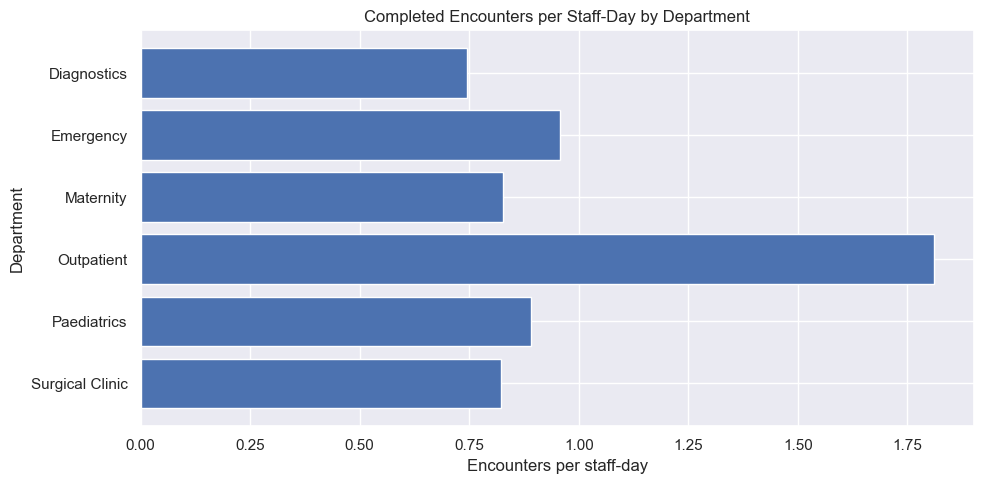

In [12]:
staffing["Date"] = pd.to_datetime(staffing["Date"], errors="coerce")
staffing_summary = staffing.groupby("Department").agg(
    PlannedStaffDays=("PlannedStaff", "sum"),
    ActualStaffDays=("StaffOnDuty", "sum"),
    OvertimeHours=("OvertimeHours", "sum"),
    PatientsSeen=("PatientsSeen", "sum")
).reset_index()
staffing_summary["StaffCoverage"] = staffing_summary["ActualStaffDays"] / staffing_summary["PlannedStaffDays"]
staffing_summary["PatientsPerStaffDay"] = staffing_summary["PatientsSeen"] / staffing_summary["ActualStaffDays"]
display(staffing_summary.round(2))
staffing_summary.to_csv(OUTPUT_DIR / "staffing_utilisation_summary.csv", index=False)

plt.figure(figsize=(10,5))
plt.barh(staffing_summary["Department"], staffing_summary["PatientsPerStaffDay"])
plt.gca().invert_yaxis()
plt.title("Completed Encounters per Staff-Day by Department")
plt.xlabel("Encounters per staff-day"); plt.ylabel("Department")
plt.tight_layout(); plt.savefig(CHART_DIR / "patients_per_staff_day.png", dpi=180); plt.show()

## 12. Build a concise KPI table

This table is a useful quality check before building the Power BI dashboard. It summarises the entire synthetic period.

In [13]:
kpi_summary = pd.DataFrame({
    "KPI": ["Total encounters", "Completed encounters", "Unique patients with a valid patient key", "Admissions",
            "Average wait (completed visits, minutes)", "Average consultation (completed visits, minutes)",
            "Average length of stay (days)", "Weighted bed occupancy", "Staff coverage"],
    "Value": [
        len(visits),
        int((visits["VisitStatus"] == "Completed").sum()),
        int(visits["PatientID"].nunique()),
        len(admissions),
        round(completed_visits["WaitMinutes"].mean(),1),
        round(completed_visits["ConsultationMinutes"].mean(),1),
        round(admissions["LengthOfStayDays"].mean(),1),
        round(facility_weighted_occupancy*100,1),
        round(staffing["StaffOnDuty"].sum()/staffing["PlannedStaff"].sum()*100,1)
    ],
    "Unit": ["encounters","encounters","patients","admissions","minutes","minutes","days","percent","percent"]
})
display(kpi_summary)
kpi_summary.to_csv(OUTPUT_DIR / "portfolio_kpi_summary.csv", index=False)

,KPI,Value,Unit
0,Total encounters,42000.0,encounters
1,Completed encounters,39441.0,encounters
2,Unique patients with a valid patient key,10762.0,patients
3,Admissions,2793.0,admissions
4,"Average wait (completed visits, minutes)",34.5,minutes
5,"Average consultation (completed visits, minutes)",24.1,minutes
6,Average length of stay (days),4.7,days
7,Weighted bed occupancy,64.3,percent
8,Staff coverage,95.9,percent


## 13. Export the cleaned and aggregated files

In [14]:
print("\nOUTPUT FILES")
for p in sorted(OUTPUT_DIR.rglob("*")):
    if p.is_file(): print(p.relative_to(PROJECT_DIR))
print("\nNotebook workflow complete. Save the notebook and keep the outputs for your report.")


OUTPUT FILES
Output\Charts\average_los_by_ward.png
Output\Charts\average_wait_by_department.png
Output\Charts\facility_bed_occupancy.png
Output\Charts\monthly_patient_visits.png
Output\Charts\patients_per_staff_day.png
Output\Charts\visits_by_department.png
Output\data_quality_audit_after_cleaning.csv
Output\data_quality_audit_before_cleaning.csv
Output\department_summary.csv
Output\length_of_stay_by_ward.csv
Output\monthly_admissions.csv
Output\monthly_visits_summary.csv
Output\portfolio_kpi_summary.csv
Output\staffing_utilisation_summary.csv
Output\visits_clean.csv
Output\waiting_time_summary.csv
Output\ward_occupancy_summary.csv

Notebook workflow complete. Save the notebook and keep the outputs for your report.
